# 第一题：使用sklearn的GaussianMixture完成聚类

实验内容：
1. 使用sklearn的GaussianMixture在Breast_Cancer_Wisconsin数据集上完成聚类任务
2. 对聚类结果可视化
3. 对比外部指标FMI和NMI
4. 选取数据集部分特征进行GaussianMixture聚类，然后对聚类结果进行可视化，并与全量特征的聚类结果进行对比分析

初始化说明：当前 Anaconda 的旧版 threadpoolctl 在 KMeans 初始化时存在 OpenBLAS 版本检测错误。本实验显式设置 `init_params="random"`，使用随机责任度初始化，然后正常执行 GMM 的 EM 训练；全量与部分特征实验均使用此设置、固定随机种子并运行 10 次初始化。无需升级全局依赖。

# 1. 导入模块

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

# 2. 导入数据集

In [2]:
# 同时支持从项目根目录和 solution 目录启动 Notebook。
from pathlib import Path

data_path = Path('data/Breast_Cancer_Wisconsin/data')
if not data_path.is_file():
    data_path = Path('../data/Breast_Cancer_Wisconsin/data')
data = pd.read_csv(data_path)
# B 表示良性，M 表示恶性；真实标签只用于评价，不参与训练。
data['diagnosis'] = data['diagnosis'].map({'B': 1, 'M': -1})

In [3]:
# 去掉患者编号和末尾全空列，保留 30 个数值特征。
data = data.values
data_x = data[:, 2:-1].astype(float)
data_y = data[:, 1].astype(int)
assert data_x.shape == (569, 30)
assert np.isfinite(data_x).all()
assert set(np.unique(data_y)) == {-1, 1}

In [4]:
print(data_x.shape)

(569, 30)


# 3. 导入模型

导入高斯混合模型模型

In [5]:
from sklearn.mixture import GaussianMixture

# 4. 训练模型

In [6]:
# 显式使用随机责任度初始化，避免旧版 threadpoolctl 在 KMeans 初始化中报错。
# 两个分量对应两个簇，固定随机种子以便重复实验。
gmm = GaussianMixture(n_components=2, random_state=42, n_init=10, init_params='random')
gmm.fit(data_x)

GaussianMixture(init_params='random', n_components=2, n_init=10,
                random_state=42)

高斯混合模型需要使用predict函数预测类标记

In [7]:
y_hat = gmm.predict(data_x)

聚类结果统计

In [8]:
def getResult(data_y,y_hat):
    true_labels = data_y.reshape(-1)
    cluster = {}
    # 构造簇
    for i in range(len(y_hat)):
        cluster_label = y_hat[i]
        if cluster_label not in cluster:
            cluster[cluster_label] = {}
    # 构造簇内类别标签
    for cluster_label in cluster:
        for true_label in list(set(true_labels)):
            cluster[cluster_label][true_label] = 0
    # 添加簇内数据
    for i in range(len(y_hat)):
            cluster_label = y_hat[i]
            cluster[cluster_label][true_labels[i]] +=1
    # 按照簇序号排序
    cluster = dict(sorted(cluster.items(),key = lambda x:x[0]))
    return cluster
cluster = getResult(data_y,y_hat)
print(cluster)

{0: {1: 323, -1: 22}, 1: {1: 34, -1: 190}}


# 5. 聚类结果可视化

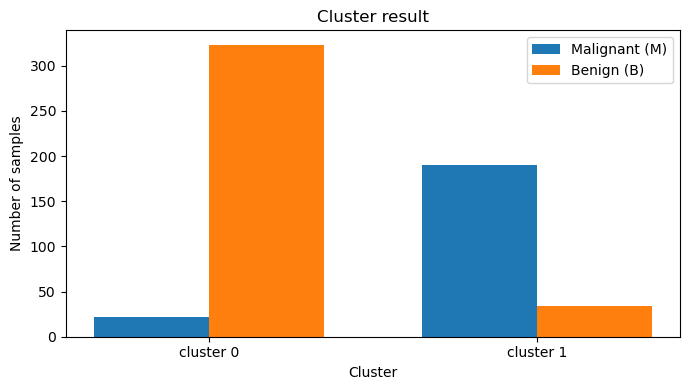

In [9]:
def draw_bar(cluster_data):
    true_labels = sorted({label for counts in cluster_data.values() for label in counts})
    cluster_labels = sorted(cluster_data)
    x = np.arange(len(cluster_labels))
    bar_width = 0.35
    plt.figure(figsize=(7, 4))
    for index, label in enumerate(true_labels):
        counts = [cluster_data[c].get(label, 0) for c in cluster_labels]
        offset = (index - (len(true_labels) - 1) / 2) * bar_width
        name = 'Benign (B)' if label == 1 else 'Malignant (M)'
        plt.bar(x + offset, counts, width=bar_width, label=name)
    plt.xticks(x, [f'cluster {c}' for c in cluster_labels])
    plt.xlabel('Cluster')
    plt.ylabel('Number of samples')
    plt.title('Cluster result')
    plt.legend()
    plt.tight_layout()
    plt.show()

draw_bar(cluster)

柱状图展示每个簇中的良性与恶性样本数。簇编号是任意的，不能直接当作诊断标签；下面使用不依赖簇编号对应关系的 NMI 和 FMI 评价聚类效果。

## 6. 指标计算

我们这里选用两个外部指标，FMI和NMI。

互信息(mutual information)表示了两个分布的一致程度。归一化的互信息(NMI)将互信息值映射到0到1的空间内。值越高，说明两个分布的一致性越高。

FMI是Fowlkes-Mallows index，使用precision和recall计算得到，其值域也是0到1，越大说明聚类效果越和参考模型相近。

In [10]:
from sklearn.metrics import normalized_mutual_info_score
from sklearn.metrics import fowlkes_mallows_score

In [11]:
normalized_mutual_info_score(data_y.reshape(-1), gmm.predict(data_x))

0.5243406017582504

In [12]:
fowlkes_mallows_score(data_y.reshape(-1), gmm.predict(data_x))

0.831274640767012

# 7. 选取数据集部分特征进行GaussianMixture聚类：并对比聚类结果

In [13]:
# 重新读取数据，用列名选取部分特征，避免误用编号或诊断列。
data = pd.read_csv(data_path)

In [14]:
# 选择平均半径和平均纹理，直接观察二维特征中的簇分布。
# 全量和部分特征实验都保留原始尺度，且使用相同样本及随机种子。
selected_features = ['radius_mean', 'texture_mean']
data_x_partial = data[selected_features].to_numpy(dtype=float)
data_y_partial = data['diagnosis'].map({'B': 1, 'M': -1}).to_numpy(dtype=int)
assert np.array_equal(data_y, data_y_partial)
print('选取特征：', selected_features)
print('部分特征数据形状：', data_x_partial.shape)

选取特征： ['radius_mean', 'texture_mean']
部分特征数据形状： (569, 2)


In [15]:
# 显式使用随机责任度初始化，避免旧版 threadpoolctl 在 KMeans 初始化中报错。
# 定义模型、训练并预测部分特征上的簇编号。
gmm_partial = GaussianMixture(n_components=2, random_state=42, n_init=10, init_params='random')
gmm_partial.fit(data_x_partial)
y_hat_partial = gmm_partial.predict(data_x_partial)

{0: {1: 314, -1: 36}, 1: {1: 43, -1: 176}}


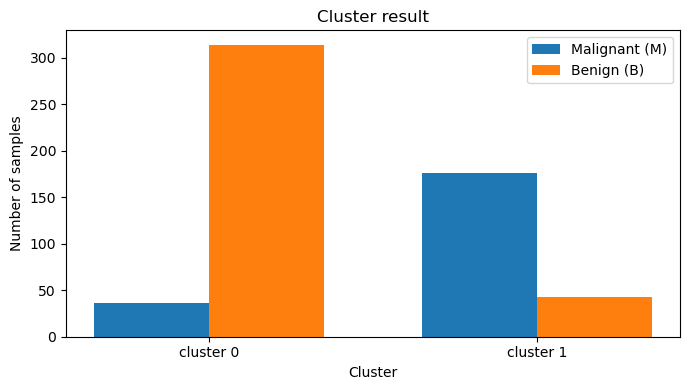

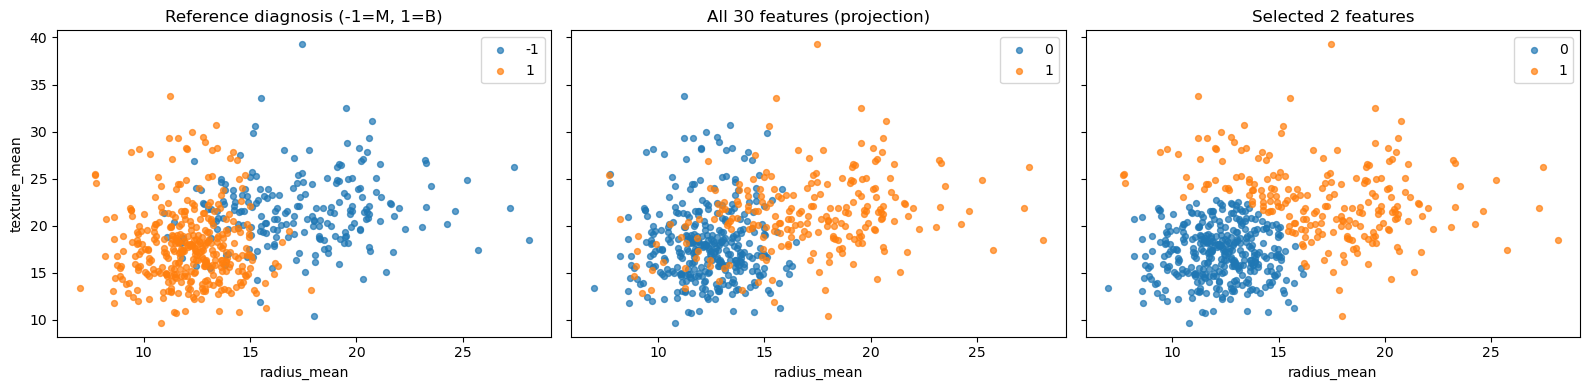

In [16]:
# 统计每个簇的真实类别构成，并绘制柱状图。
cluster_partial = getResult(data_y_partial, y_hat_partial)
print(cluster_partial)
draw_bar(cluster_partial)

# 用相同的二维坐标对比全量特征的聚类投影和部分特征的聚类。
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, labels, title in zip(
    axes,
    [data_y_partial, y_hat, y_hat_partial],
    ['Reference diagnosis (-1=M, 1=B)', 'All 30 features (projection)', 'Selected 2 features']
):
    for label in np.unique(labels):
        mask = labels == label
        ax.scatter(data_x_partial[mask, 0], data_x_partial[mask, 1], s=18, alpha=0.7, label=str(label))
    ax.set_xlabel(selected_features[0])
    ax.set_title(title)
    ax.legend()
axes[0].set_ylabel(selected_features[1])
plt.tight_layout()
plt.show()

In [17]:
# 计算全量与部分特征的 FMI、NMI，并列比较。
comparison = pd.DataFrame({
    '特征设置': ['全部 30 个特征', 'radius_mean + texture_mean'],
    'FMI': [fowlkes_mallows_score(data_y, y_hat),
            fowlkes_mallows_score(data_y_partial, y_hat_partial)],
    'NMI': [normalized_mutual_info_score(data_y, y_hat),
            normalized_mutual_info_score(data_y_partial, y_hat_partial)]
}).set_index('特征设置')
display(comparison.round(6))
for metric in ['FMI', 'NMI']:
    difference = comparison.iloc[1][metric] - comparison.iloc[0][metric]
    trend = '提高' if difference > 0 else '降低' if difference < 0 else '持平'
    print(f'部分特征的 {metric} 相比全量特征{trend}，差值为 {difference:+.6f}。')

,FMI,NMI
特征设置,,
全部 30 个特征,0.831275,0.524341
radius_mean + texture_mean,0.773450,0.400818


部分特征的 FMI 相比全量特征降低，差值为 -0.057825。
部分特征的 NMI 相比全量特征降低，差值为 -0.123523。


本次随机初始化的运行结果：全量特征 FMI = 0.831275、NMI = 0.524341；两个特征 FMI = 0.773450、NMI = 0.400818。减少特征后两个指标均下降，当前设置下全量特征的结果更符合真实诊断。初始化方法改变后可能收敛到不同的局部最优，因此本次指标与原先 KMeans 初始化的结果有所不同。

对比分析：上表和输出分别给出两种特征设置的 FMI、NMI 及差值；两个指标越大，聚类与真实诊断类别越一致。两个指标衡量的方面不同，不能直接比较 FMI 与 NMI 的绝对大小。只选取平均半径和平均纹理会减少信息，同时改变特征对模型的影响，因此应结合两个指标判断效果，不能预先断言全量特征一定更好。

散点图中的全量结果是在同一二维坐标上的投影，聚类实际使用了 30 个特征；簇编号本身没有良恶性的含义。为遵循给定实验代码，本实验未标准化特征，KMeans 的欧氏距离容易受到面积等大尺度特征主导，GMM 的协方差估计也受特征尺度和初始化影响。结论限于当前特征选择、原始尺度和随机种子；可以进一步标准化后重新训练，检验结论是否稳定。